In [153]:
import jax
from ott.geometry import pointcloud
from ott.solvers.linear import sinkhorn
from ott.tools import sinkhorn_divergence as sdiv
import time
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import pairwise_distances
from tqdm import tqdm

In [112]:
epsilon = 1

In [157]:
results_ot = dict()
results_pw_dist = dict()
for n in [10,100]:
    results_ot[n] = list()
    results_pw_dist[n] = list()
    for i in tqdm(range(0,100)):
        rngs = jax.random.split(jax.random.PRNGKey(i), 2)
        d, n_x, n_y = 2, n, n
        x = jax.random.normal(rngs[0], (n_x, d))
        y = jax.random.normal(rngs[1], (n_y, d)) + 1
        # geom = pointcloud.PointCloud(x, y, epsilon=epsilon)
        # solve_fn = jax.jit(sinkhorn.solve)
        # # st = time.time()
        # ot_2 = solve_fn(geom, a=None, b=None)
        # et = time.time()
        # print('Execution time:', et-st, 'seconds or', time.strftime("%H:%M:%S", time.gmtime(et - st)))
        # results_ot[n].append(ot_2.kl_reg_cost)
        output = sdiv.sinkhorn_divergence(
            pointcloud.PointCloud,
            x=x,
            y=y,
            epsilon=epsilon,
        )
        results_ot[n].append(output.divergence)
        results_pw_dist[n].append(pairwise_distances(x,y).mean())

100%|██████████| 100/100 [02:35<00:00,  1.55s/it]


In [141]:
ot_2.kl_reg_cost

Array(3.8973727, dtype=float32)

In [142]:
ot_2.primal_cost

Array(2.989506, dtype=float32)

In [143]:
ot_2.dual_cost

Array(-9.9181385, dtype=float32)

In [144]:
ot_2.ent_reg_cost

Array(-9.9181385, dtype=float32)

In [147]:
ot_2.reg_ot_cost

Array(3.8973727, dtype=float32)

In [146]:
output.divergence

Array(2.121378, dtype=float32)

In [160]:
results_df_ot = pd.DataFrame({'x':np.array(100*[10] + 100*[100]), 'y':np.array(results_ot[10] + results_ot[100])})
# results_df_ot = pd.DataFrame({'x':np.array(100*[10] + 100*[100] + 100*[1000]), 'y':np.array(results_ot[10] + results_ot[100] + results_ot[1000])})
results_df_pw_dist = pd.DataFrame({'x':np.array(100*[10] + 100*[100]), 'y':np.array(results_pw_dist[10] + results_pw_dist[100])})

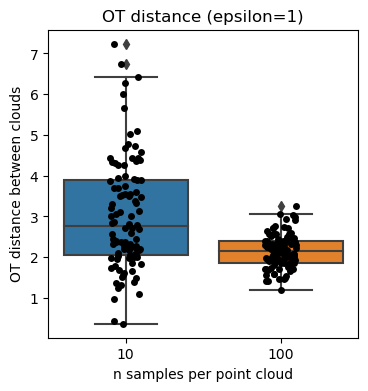

In [161]:
fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot()
sns.boxplot(results_df_ot, x='x',y='y',ax=ax)
sns.stripplot(results_df_ot, x='x',y='y',color='black',ax=ax)
ax.set_xlabel('n samples per point cloud')
ax.set_ylabel('OT distance between clouds')
ax.set_title(f'OT distance (epsilon={epsilon})')
plt.show()

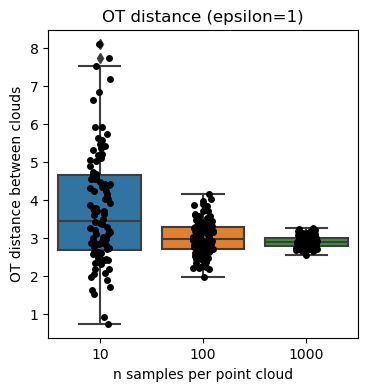

In [120]:
fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot()
sns.boxplot(results_df_ot, x='x',y='y',ax=ax)
sns.stripplot(results_df_ot, x='x',y='y',color='black',ax=ax)
ax.set_xlabel('n samples per point cloud')
ax.set_ylabel('OT distance between clouds')
ax.set_title(f'OT distance (epsilon={epsilon})')
plt.show()

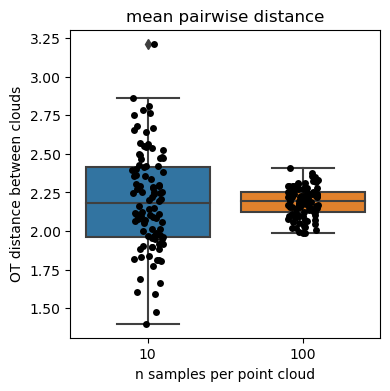

In [121]:
fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot()
sns.boxplot(results_df_pw_dist, x='x',y='y',ax=ax)
sns.stripplot(results_df_pw_dist, x='x',y='y',color='black',ax=ax)
ax.set_xlabel('n samples per point cloud')
ax.set_ylabel('mean pairwise distance between clouds') # update plot with correct ylabel
ax.set_title('mean pairwise distance')
plt.show()

In [122]:
np.sqrt(1**2 + 1**2)

1.4142135623730951

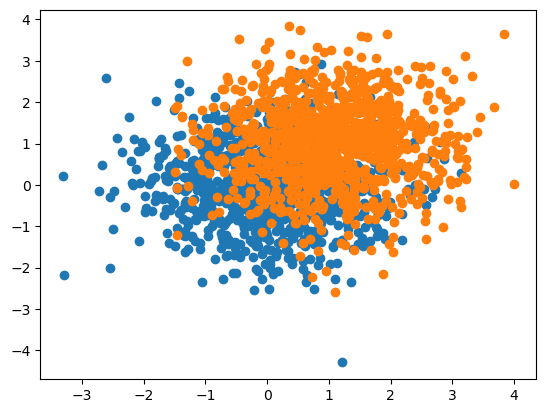

In [123]:
plt.scatter(x[:,0], x[:,1])
plt.scatter(y[:,0], y[:,1])

<Axes: >

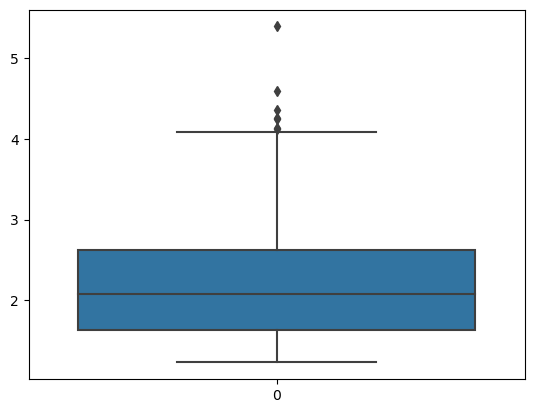

In [124]:
sns.boxplot(pairwise_distances(x,y).mean(axis=0))